# EDA — Malla peatonal y semaforos

Este cuaderno realiza el **Análisis Exploratorio de Datos (EDA)** de las dos capas geoespaciales base del proyecto:

1. **Malla peatonal de Bogotá D.C.** (`red_peatonal_conexion (1).gpkg`)
2. **Semaforos** (`semaforos_bogota.geojson`) 

El cuaderno está organizado así:

1. Diccionario de variables (Malla peatonal y semaforos)
2. Carga de librerías y datos
3. EDA — Malla peatonal
4. EDA — Semáforos
5. Exportación de capas procesadas (salida final)

## 1. Diccionario de variables

### 1.1 Malla peatonal

| Variable | Tipo | Descripción |
|---|---|---|
| 'OBJECTID' | int | Identificador único interno del registro (ArcGIS). |
| 'CODIGO_ID' | str | Código de identificación asociado al elemento de la red peatonal. |
| 'TEMA' | str | Componente temático de la estructura territorial al que pertenece el elemento. |
| 'ELEMENTO' | str | Sistema o componente de infraestructura al que pertenece el registro. |
| 'NOMBRE' | str | Nombre o identificación del segmento (Ejemplo: 'AVENIDA CIUDAD MONTES') |
| 'CLASIFICACION' | str/object | Clasificación específica del elemento dentro de la red peatonal. |
| 'ESTADO' | float | Estado o condición registrada para el elemento. En los datos observados presenta valores nulos. |
| 'ACTO_ADMINISTRATIVO' | str | Tipo o abreviatura del acto administrativo asociado al elemento. En los registros observados aparece 'DEC'. |
| 'NUMERO_ACTO_ADMINISTRATIVO' | str | Número del acto administrativo asociado al registro. En los datos observados corresponde a '555'. |
| 'FECHA_ACTO_ADMINISTRATIVO' | datetime64[ms] | Fecha correspondiente al acto administrativo asociado al elemento. |
| 'NORMATIVA' | str | Descripción de la normativa que sustenta o enmarca la información registrada. |
| 'OBSERVACION' | object | Campo destinado a registrar observaciones o información adicional sobre el elemento. |
| 'ESCALA_CAPTURA' | object | Escala utilizada para la captura o generación de la información geográfica. |
| 'FECHA_CAPTURA' | datetime64[ms] | Fecha en la que fue capturada o registrada la información geográfica. |
| 'RESPONSABLE' | str | Identificador o código asociado al responsable de la información registrada. |
| 'Shape_Length' | float64 | Longitud de la geometría lineal correspondiente al segmento de la red peatonal. |
| 'geometry' | geometry | Geometría espacial del elemento. Los registros corresponden a geometrías MULTILINESTRING que representan segmentos de la red peatonal. |


### 1.2 Semaforos

| Variable | Tipo | Descripción |
|---|---|---|
| 'OBJECTID' | int | Número único que identifica los elementos dentro de la base de datos. |
| 'ID' | int | Código numérico asignado a una intersección semaforizada específica, en una dirección única. |
| 'EXTERNO' | int | Código numérico de 4 dígitos asignado a un equipo de control que puede operar una o más intersecciones semafóricas. |
| 'DIRECCION' | str | Nomenclatura de referencia para la ubicación de una intersección semaforizada. |
| 'LOCALIDAD' | str | División político-administrativa de Bogotá D.C. a la que pertenece la intersección semaforizada. |
| 'EQUIPO' | str | Tipo de equipo de control con el cual se gestiona el funcionamiento de la intersección de referencia. |
| 'NUMEROINTERSECCIONES_POREQUIPO' | str | Cantidad de intersecciones con código ID que puede gestionar el equipo de control implementado. |
| 'UBICACIONEQUIPO' | str | Indica si el equipo de control se encuentra ubicado en la ubicación de referencia. |
| 'FECHAINSTALACION' | datetime | Fecha de entrada en operación de la intersección semaforizada. |
| 'OPERACIONACTUAL' | str | Estado de tránsito bajo el cual se encuentra funcionando la intersección semafórica. |
| 'FUNCIONAMIENTO' | str | Combinación de las diferentes estrategias de control utilizadas a nivel del controlador y de la central. |
| 'IMPLEMENTACION' | str | Estado bajo el cual se implementa la intersección semafórica. |
| 'TIPOINTERSECCION' | str | Funcionamiento de la intersección semafórica de acuerdo con el tipo o tipos de usuario que regula. |
| 'GRUPOSENALES' | int | Cantidad de entradas y salidas de una intersección semafórica que posee la dirección de referencia. |
| 'TOTALGRUPOSENALES' | int | Cantidad de entradas y salidas implementadas y operativas en el equipo de control para el externo de referencia. |
| 'NUMEROFASES' | int | Cantidad de estados de señales mediante los cuales se asigna simultáneamente el derecho de paso a uno o varios grupos vehiculares o peatonales no conflictivos. |
| 'GRUPOSVEHICULARES' | str | Nomenclatura asignada a cada paso de uso exclusivamente vehicular. |
| 'GRUPOS_BRT' | str | Nomenclatura asignada a cada paso de uso exclusivamente por bus articulado. |
| 'GRUPOSPEATONALES' | str | Nomenclatura asignada a cada paso de uso exclusivamente peatonal. |
| 'GRUPOSSONOROS' | str | Nomenclatura asignada a cada paso de uso exclusivamente para peatones en condición de discapacidad visual. |
| 'GRUPOSCICLISTAS' | str | Nomenclatura asignada a cada paso de uso exclusivamente ciclista. |
| 'CANTIDADCONTADORES' | int | Cantidad de dispositivos de conteo regresivo implementados en la intersección semafórica de referencia. |
| 'FUNCIONDETECTORES' | int | Modo de operación programado para el uso de los detectores instalados en la intersección semafórica de referencia. |
| 'ZONAAUTOMATICA' | str | Número de 4 dígitos asignado a una zona que puede contener varias intersecciones semafóricas que operan en conjunto. |
| 'geometry' | geometry | Geometría espacial que representa la ubicación de la intersección semaforizada dentro de la red. |

#### **Diccionario de Variables: Columna `FUNCIONAMIENTO`**

**Definición del Dominio:** Posibles combinaciones entre las diferentes estrategias de control a nivel de controlador local y a nivel de central, que permiten gestionar de manera más eficiente las diferentes operaciones de la intersección semafórica *(Fuente: Documento Institucional GIG-06-FR-02 V.2)*.

| Código | Estrategia en Central | Estrategia en Controlador | Descripción de la Operación Semafórica | Frecuencia |
| :---: | :--- | :--- | :--- | :---: |
| **BT-TF** | Basado en Tiempo (`BT`) | Tiempos Fijos (`TF`) | Selección de planes por horario desde la central + ejecución fija preestablecida en el controlador. | 508 |
| **BT-TA** | Basado en Tiempo (`BT`) | Tráfico Actuado (`TA`) | Selección de planes por horario desde la central + optimización por algoritmo y detectores en el sitio. | 328 |
| **CA-TA** | Central Adaptativo (`CA`) | Tráfico Actuado (`TA`) | Ajuste en tiempo real de verdes/fases por detectores en central + optimización variable en el controlador. | 306 |
| **RP-TF** | Responsivo (`RP`) | Tiempos Fijos (`TF`) | Selección responsiva de planes enviada desde central según detectores + ejecución fija en el sitio. | 281 |
| **R-TF** | Responsivo (`R`) | Tiempos Fijos (`TF`) | Cambio de planes activado por demanda de tráfico + regulación constante en el controlador. | 107 |
| **R-TA** | Responsivo (`R`) | Tráfico Actuado (`TA`) | Cambio de planes activado por demanda de tráfico + ajuste por algoritmo/detectores en el sitio. | 103 |
| **RP-TA** | Responsivo (`RP`) | Tráfico Actuado (`TA`) | Selección responsiva desde central + optimización variable por detectores en el sitio. | 100 |
| **CA-TF** | Central Adaptativo (`CA`) | Tiempos Fijos (`TF`) | Control adaptativo dinámico en central + tiempos preestablecidos locales en el controlador. | 12 |

---

#### **Nomenclatura de Estrategias de Control:**

* **Control a Nivel de Central (Primeras Siglas):**
  * `BT` (**Basado en el Tiempo**): Mecanismo de selección de planes de señales activados en función de un horario o día específico.
  * `CA` (**Central Adaptativo**): Modo de control que ajusta los planes de señales basándose en las condiciones del tránsito registradas por los detectores (ajuste de tiempos de luz verde y otras acciones).
  * `RP` / `R` (**Responsivo**): Mecanismo de selección que ajusta los planes enviando órdenes de cambio a un plan determinado según las condiciones del tránsito registradas por detectores.

* **Control a Nivel de Controlador / Local (Segundas Siglas):**
  * `TA` (**Tráfico Actuado**): Control basado en programación variable accazada por un algoritmo en el controlador, optimizando la operación según las variables del tránsito detectadas en el sitio.
  * `TF` (**Tiempos Fijos**): Programación fija de planes que cambian de forma preestablecida en el controlador de manera constante y predecible, sin depender del tráfico en tiempo real.

## 2. Carga de librerías y datos

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.validation import explain_validity
import os


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
#Datos
peatonal = gpd.read_file("Data/raw/red_peatonal_conexion (1).gpkg")
semaforos = gpd.read_file("Data/raw/semaforos_bogota.geojson")

In [3]:
## Fecha de instalación de los semáforos (sección 3.3.1 del documento)
fecha_inst = pd.to_datetime(semaforos['FECHAINSTALACION'], errors='coerce', utc=True)
periodo = pd.cut(fecha_inst.dt.year, [0, 2014, 2020, 9999], labels=['2014 o antes', '2015-2020', '2021 o después'])
resumen_inst = periodo.value_counts().sort_index().to_frame('n')
resumen_inst['%'] = (100 * resumen_inst['n'] / resumen_inst['n'].sum()).round(1)
print(f"Semáforos: {len(semaforos):,} | sin fecha: {fecha_inst.isna().sum()}")
print(resumen_inst.to_string())


Semáforos: 1,745 | sin fecha: 0
                     n     %
FECHAINSTALACION            
2014 o antes      1250  71.6
2015-2020          218  12.5
2021 o después     277  15.9


In [4]:
print("CRS red peatonal:", peatonal.crs)
print("CRS semaforos:", semaforos.crs)

CRS red peatonal: PROJCS["PCS_CarMAGBOG",GEOGCS["GCS_CarMAGBOG",DATUM["CGS_CarMAGBOG",SPHEROID["GRS80 Mod",6380687,298.257222101]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",4.680486111],PARAMETER["central_meridian",-74.14659167],PARAMETER["scale_factor",1],PARAMETER["false_easting",92334.879],PARAMETER["false_northing",109320.965],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
CRS semaforos: EPSG:4326


### 2.1 Estandarización de CRS

La malla peatonal llega en un sistema proyectado local (CarMAGBOG, Transversal de Mercator, unidades
en metros) y los semáforos en coordenadas geográficas (EPSG:4326, grados). Al ser sistemas distintos,
cualquier operación espacial conjunta (uniones, distancias, buffers) daría resultados erróneos. Por eso
**al inicio de este cuaderno ambas capas se reproyectan a `EPSG:3116`** (MAGNA-SIRGAS / Colombia
Bogotá), sistema proyectado con unidades en metros.


In [5]:
# Proyectar ambas capas a EPSG:3116
peatonal = peatonal.to_crs(epsg=3116)
semaforos = semaforos.to_crs(epsg=3116)

# Verificar
print("CRS red peatona:", peatonal.crs)
print("CRS semáforos:", semaforos.crs)

CRS red peatona: EPSG:3116
CRS semáforos: EPSG:3116


In [6]:
# Validaciones de la reproyección: fallan de forma visible si algo va mal
XMIN, XMAX, YMIN, YMAX = 950_000, 1_050_000, 950_000, 1_060_000

xmin, ymin, xmax, ymax = peatonal.total_bounds
print("Bounds malla peatonal (3116):", (round(xmin), round(ymin), round(xmax), round(ymax)))
assert XMIN < xmin and xmax < XMAX and YMIN < ymin and ymax < YMAX, \
    "Malla peatonal fuera del rango esperado en EPSG:3116"

# Semáforos: se reporta en vez de fallar, porque la fuente trae registros con coordenadas corruptas
fuera_sem = ~(semaforos.geometry.x.between(XMIN, XMAX) & semaforos.geometry.y.between(YMIN, YMAX))
print(f"Semáforos fuera del rango esperado: {fuera_sem.sum()} de {len(semaforos)}")
assert fuera_sem.mean() < 0.01, "Demasiados semáforos fuera de rango: revisar CRS"

# La longitud recalculada debe ser coherente con Shape_Length original
ratio = (peatonal.length / peatonal["Shape_Length"]).describe()
print(ratio.round(4))
assert 0.99 < ratio["50%"] < 1.01, "La reproyección de la malla altera las longitudes: revisar transformación"

Bounds malla peatonal (3116): (984868, 986922, 1007036, 1024810)
Semáforos fuera del rango esperado: 1 de 1745
count    46065.0000
mean         0.9996
std          0.0000
min          0.9996
25%          0.9996
50%          0.9996
75%          0.9996
max          0.9996
dtype: float64


## 3. EDA — Malla Peatonal

### 3.1  Informacion general de los datos

In [7]:
print("Tipo de geometría:", peatonal.geom_type.unique())
peatonal.info()

Tipo de geometría: <ArrowStringArray>
['MultiLineString']
Length: 1, dtype: str
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 46065 entries, 0 to 46064
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   OBJECTID                    46065 non-null  int64         
 1   CODIGO_ID                   46065 non-null  str           
 2   TEMA                        46065 non-null  str           
 3   ELEMENTO                    46065 non-null  str           
 4   NOMBRE                      46065 non-null  str           
 5   CLASIFICACION               0 non-null      object        
 6   ESTADO                      0 non-null      float64       
 7   ACTO_ADMINISTRATIVO         46065 non-null  str           
 8   NUMERO_ACTO_ADMINISTRATIVO  46065 non-null  str           
 9   FECHA_ACTO_ADMINISTRATIVO   46065 non-null  datetime64[ms]
 10  NORMATIVA                   46

### 3.2 Valores faltantes

In [8]:
nan_count = peatonal.isna().sum()

# Filtrar las columnas donde el conteo de NaN es mayor que 0
faltantes = pd.DataFrame(nan_count[nan_count > 0])

# Calcular el porcentaje de valores faltantes
faltantes["%"] = (faltantes[0] / len(peatonal)) * 100

# Imprimir el resultado
faltantes

,0,%
CLASIFICACION,46065,100.0
ESTADO,46065,100.0
OBSERVACION,46065,100.0
ESCALA_CAPTURA,46065,100.0


In [9]:
peatonal = peatonal.drop(columns=['CLASIFICACION','ESTADO','OBSERVACION','ESCALA_CAPTURA'])

#### Dado que en las 4 columnas tenemos el 100% de valores faltantes es informacion que no aporta al estudio se omite.
#### Revisaremos ahora constantes del conjunto de datos.

In [10]:
def entropia(datos):
    # Forzar la conversión de todo el vector a string explícito
    datos_str = np.asarray(datos, dtype=str)
    valores, frecuencias = np.unique(datos_str, return_counts=True)
    probabilidades = frecuencias / len(datos_str)
    ent = -np.sum(probabilidades * np.log2(probabilidades, where=(probabilidades > 0)))
    frecuencias_individuales = dict(zip(valores, frecuencias))
    return ent, frecuencias_individuales

entropia_original = peatonal.copy()
resultados_entropia = []
for columna in peatonal.columns:
    entropia_original[columna] = entropia_original[columna].astype(str) # Convertir a string para evitar problemas con diferentes tipos
    cat_entropia, diccionario = entropia(entropia_original[columna])

    # Encontrar la categoría dominante
    categoria_dominante = max(diccionario, key=lambda k: diccionario[k])

    # Almacenar los resultados
    resultados_entropia.append({
        'Variable': columna,
        'Entropia': cat_entropia,
        'Categoria dominante': categoria_dominante
    })

entropia_tabla = pd.DataFrame(resultados_entropia)
entropia_tabla = entropia_tabla.sort_values(by='Entropia', ascending=False)
entropia_tabla

C:\Users\Brayan\AppData\Local\Temp\ipykernel_17608\1347095167.py:6: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  ent = -np.sum(probabilidades * np.log2(probabilidades, where=(probabilidades > 0)))
C:\Users\Brayan\AppData\Local\Temp\ipykernel_17608\1347095167.py:6: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  ent = -np.sum(probabilidades * np.log2(probabilidades, where=(probabilidades > 0)))
C:\Users\Brayan\AppData\Local\Temp\ipykernel_17608\1347095167.py:6: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  ent = -np.sum(probabilidades * np.log2(probabilidades, where=(probabilidades > 0)))
C:\Users\Brayan\AppData\Local\Temp\ipykernel_17608\1347095167.py:6: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None

,Variable,Entropia,Categoria dominante
0,OBJECTID,15.491383,1
1,CODIGO_ID,15.491383,1
12,geometry,15.491383,MULTILINESTRING ((1000000.326607 998776.461538...
11,Shape_Length,15.490428,10.081022431722428
4,NOMBRE,3.562000,SIN_NMG
3,ELEMENTO,-0.000000,Sistema de Espacio Público Peatonal y para el ...
2,TEMA,-0.000000,Estructura Funcional y del Cuidado
5,ACTO_ADMINISTRATIVO,-0.000000,DEC
6,NUMERO_ACTO_ADMINISTRATIVO,-0.000000,555
8,NORMATIVA,-0.000000,En el marco del Decreto 555 del 29 de diciembr...


In [11]:
entropia_original["NOMBRE"].unique()

<ArrowStringArray>
[                         'SIN_NMG',            'AVENIDA CIUDAD MONTES',
  'AVENIDA CIUDAD DE VILLAVICENCIO',      'AVENIDA FERROCARRIL DEL SUR',
          'AVENIDA CIUDAD DE QUITO',        'AVENIDA GERMAN ARCINIEGAS',
 'AVENIDA FERROCARRIL DE OCCIDENTE',          'AVENIDA PRIMERO DE MAYO',
           'AVENIDA DE LOS MUISCAS',                   'AVENIDA BOYACA',
 ...
        'AVENIDA LUIS CARLOS GALAN',                  'AVENIDA BOLIVIA',
                  'AVENIDA DEL TAM',            'AVENIDA GONZALO ARIZA',
                'AVENIDA VERSALLES',          'AVENIDA DE LA ESPERANZA',
               'AVENIDA EL CORTIJO',              'AVENIDA CARRERA 103',
           'AVENIDA DARIO ECHANDIA',               'AVENIDA LA FISCALA']
Length: 120, dtype: str

#### Las variables no aportaban informacion para el estudio, con una entropia 0 nos indica que no hay variabilidad dentro de la variable, en todos sus registros tiene el mismo valo, por esta razon se     omiten tambien, teniendo en cuenta que son variables de informacion referente a la construccion de la base de datos [**ACTO_ADMINISTRATIVO,NUMERO_ACTO_ADMINISTRATIVO,NORMATIVA,FECHA_ACTO_ADMINISTRATIVO,FECHA_CAPTURA,RESPONSABLE**] estas variables hacen referencia al marco juridico por el cual se realizo esta toma de datos, en que momento y quien la hizo, para nuestro modelado no es importante tenerlas en cuenta ya que no aportan valor estadistico.

In [12]:
peatonal = peatonal[["OBJECTID","CODIGO_ID","NOMBRE", "Shape_Length", "geometry"]].copy()
print(peatonal.nunique()) 

OBJECTID        46065
CODIGO_ID       46065
NOMBRE            120
Shape_Length    46043
geometry        46065
dtype: int64


In [13]:
for i in peatonal.columns:
    print("**********************")
    print(peatonal[i].value_counts())
    print("*********** Nueva columna ***********")

**********************
OBJECTID
1        1
2        1
3        1
4        1
5        1
        ..
46061    1
46062    1
46063    1
46064    1
46065    1
Name: count, Length: 46065, dtype: int64
*********** Nueva columna ***********
**********************
CODIGO_ID
1        1
2        1
3        1
4        1
5        1
        ..
46061    1
46062    1
46063    1
46064    1
46065    1
Name: count, Length: 46065, dtype: int64
*********** Nueva columna ***********
**********************
NOMBRE
SIN_NMG                              26330
AVENIDA BOYACA                        1236
AVENIDA CARACAS                       1231
AVENIDA PASEO DE LOS LIBERTADORES     1061
AVENIDA CIUDAD DE QUITO                871
                                     ...  
AVENIDA EL CORTIJO                      11
AVENIDA FEDERICO LLERAS                  9
AVENIDA TIBABITA                         9
AVENIDA LA FISCALA                       6
AVENIDA CONGRESO EUCARISTICO             5
Name: count, Length: 120, dtype:

### 3.3 Verficacion de nulos en geometry o valores no concordantes

In [14]:
# --- Malla peatonal ---
peatonal["es_valida"] = peatonal.geometry.is_valid
peatonal["es_vacia"]  = peatonal.geometry.is_empty

print("Geometrías inválidas (peatonal):", (~peatonal["es_valida"]).sum())
print("Geometrías vacías (peatonal):", peatonal["es_vacia"].sum())

if (~peatonal["es_valida"]).any():
    invalidas = peatonal.loc[~peatonal["es_valida"], ["OBJECTID", "geometry"]].copy()
    invalidas["motivo"] = invalidas.geometry.apply(explain_validity)
    display(invalidas)

Geometrías inválidas (peatonal): 0
Geometrías vacías (peatonal): 0


In [15]:
peatonal.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 46065 entries, 0 to 46064
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   OBJECTID      46065 non-null  int64   
 1   CODIGO_ID     46065 non-null  str     
 2   NOMBRE        46065 non-null  str     
 3   Shape_Length  46065 non-null  float64 
 4   geometry      46065 non-null  geometry
 5   es_valida     46065 non-null  bool    
 6   es_vacia      46065 non-null  bool    
dtypes: bool(2), float64(1), geometry(1), int64(1), str(2)
memory usage: 2.6 MB


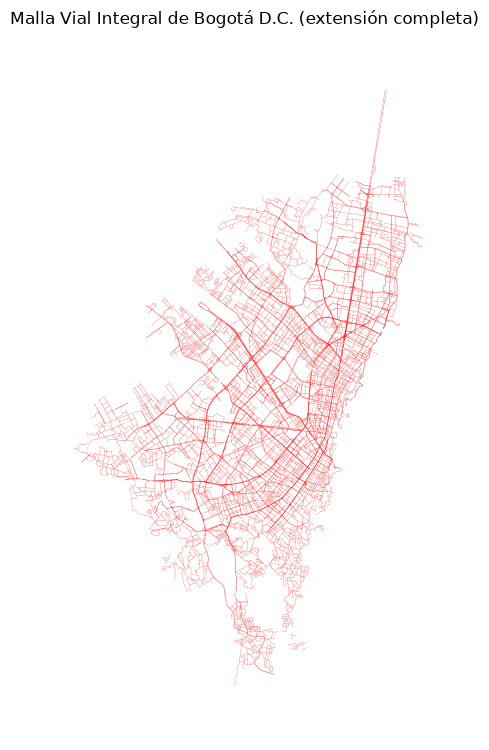

In [16]:
fig, ax = plt.subplots(figsize=(9, 9))
peatonal.plot(ax=ax, linewidth=0.15, color='red')
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial Integral de Bogotá D.C. (extensión completa)')
ax.set_axis_off()
plt.show()

## 4. EDA — Semaforos

In [17]:
print("Tipo de geometría:", semaforos.geom_type.unique())
semaforos.info()

Tipo de geometría: <ArrowStringArray>
['Point']
Length: 1, dtype: str
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1745 entries, 0 to 1744
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype              
---  ------                          --------------  -----              
 0   OBJECTID                        1745 non-null   int32              
 1   ID                              1745 non-null   int32              
 2   EXTERNO                         1745 non-null   int32              
 3   DIRECCION                       1745 non-null   str                
 4   LOCALIDAD                       1745 non-null   str                
 5   EQUIPO                          1745 non-null   str                
 6   NUMEROINTERSECCIONES_POREQUIPO  1745 non-null   str                
 7   UBICACIONEQUIPO                 1745 non-null   str                
 8   FECHAINSTALACION                1745 non-null   datetime64[ms, UTC]
 9   OPERACI

#### El porcentaje de faltantes es menor que 1% mantenemos las variables.

In [18]:
entropia_original_2 = semaforos.copy()
resultados_entropia_2 = []

for columna in semaforos.columns:
    # Llamada a la función con el vector limpio
    cat_entropia, diccionario = entropia(entropia_original_2[columna])

    # Encontrar la categoría dominante
    categoria_dominante = max(diccionario, key=lambda k: diccionario[k])

    # Almacenar los resultados
    resultados_entropia_2.append({
        'Variable': columna,
        'Entropia': cat_entropia,
        'Categoria dominante': categoria_dominante
    })

entropia_tabla_2 = pd.DataFrame(resultados_entropia_2)
entropia_tabla_2 = entropia_tabla_2.sort_values(by='Entropia', ascending=False).reset_index(drop=True)

entropia_tabla_2

C:\Users\Brayan\AppData\Local\Temp\ipykernel_17608\1347095167.py:6: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  ent = -np.sum(probabilidades * np.log2(probabilidades, where=(probabilidades > 0)))


,Variable,Entropia,Categoria dominante
0,OBJECTID,10.769011,1
1,ID,10.769011,1
2,geometry,10.769011,POINT Z (1000003.9244324092 999810.9051570676 0)
3,DIRECCION,10.767865,KR 5D X AC 51 S
4,EXTERNO,10.373262,3797
5,FECHAINSTALACION,9.882345,1998-09-05 00:00:00+00:00
6,GRUPOSPEATONALES,8.711752,"21,22,23,24"
7,GRUPOSVEHICULARES,8.231082,"1,2,3,4"
8,ZONAAUTOMATICA,7.084600,2708
9,TOTALGRUPOSENALES,4.349164,8


#### Se calcula tambien la categoria dominante por si existen nulos que no estan identificados como np.nan. No omitimos variables por entropia ninguna cae en un valor constante. Se procede a revisar las variables que pueden tener valores faltantes ocultos.

In [19]:
columnas_imputar = semaforos.columns
semaforos[columnas_imputar] = semaforos[columnas_imputar].replace(['N/A', 'n/a', 'N/D', 'NONE', 'None', ''], np.nan)
nan_count = semaforos.isna().sum()

# 2. Construir el DataFrame de valores faltantes
faltantes2 = pd.DataFrame({
    'Cantidad': nan_count,
    '% Faltantes': (nan_count / len(semaforos)) * 100
})

faltantes2 = faltantes2[faltantes2['Cantidad'] > 0]

faltantes2 = faltantes2.sort_values(by='Cantidad', ascending=False)

faltantes2

,Cantidad,% Faltantes
GRUPOS_BRT,1538,88.137536
GRUPOSSONOROS,1284,73.581662
FUNCIONDETECTORES,833,47.736390
GRUPOSPEATONALES,40,2.292264
GRUPOSVEHICULARES,24,1.375358
GRUPOSCICLISTAS,8,0.458453


In [20]:
# Lista de variables a imputar
columnas_imputar = [
    'GRUPOSVEHICULARES',
    'GRUPOSPEATONALES',
    'GRUPOSCICLISTAS'
]

for col in columnas_imputar:
    if col in semaforos.columns:
        # Intentar conversión temporal a numérico para evaluar el tipo real de la columna
        serie_num = pd.to_numeric(semaforos[col], errors='coerce')
        
        # Si la mayoría de los valores no nulos son numéricos, se trata como columna numérica
        if serie_num.notna().sum() > 0 and (serie_num.notna().sum() >= semaforos[col].notna().sum() * 0.8):
            semaforos[col] = serie_num
            media_val = semaforos[col].mean()
            
            # Si los datos originales son enteros (ej. conteos), redondear la media
            if (semaforos[col].dropna() % 1 == 0).all():
                media_val = round(media_val)
                
            semaforos[col] = semaforos[col].fillna(media_val)
            print(f"Columna NUMÉRICA '{col}' imputada con la media: {media_val}")
            
        else:
            # Si es categórica o texto, imputar con la moda
            moda_series = semaforos[col].mode()
            if not moda_series.empty:
                moda_val = moda_series[0]
                semaforos[col] = semaforos[col].fillna(moda_val)
                print(f"Columna CATEGÓRICA '{col}' imputada con la moda: '{moda_val}'")
            else:
                print(f"Columna '{col}' no tiene moda disponible para imputar.")

# Verificar que ya no existan valores nulos en estas columnas
print("\nValores faltantes restantes:")
print(semaforos[columnas_imputar].isna().sum())

Columna CATEGÓRICA 'GRUPOSVEHICULARES' imputada con la moda: '1,2,3,4'
Columna CATEGÓRICA 'GRUPOSPEATONALES' imputada con la moda: '21,22,23,24'
Columna CATEGÓRICA 'GRUPOSCICLISTAS' imputada con la moda: 'NO'

Valores faltantes restantes:
GRUPOSVEHICULARES    0
GRUPOSPEATONALES     0
GRUPOSCICLISTAS      0
dtype: int64


#### Con el analisis de entropia y luego verificacion de cateogria dominante se logro determibar esos casos donde los valores no estaban como np.nan.
#### Se imputa con la media o moda dado el caso.

### 4.1 Validar geometry en semaforos

In [21]:
semaforos["es_valida"] = semaforos.geometry.is_valid
semaforos["es_vacia"]  = semaforos.geometry.is_empty

print("Geometrías inválidas (semáforos):", (~semaforos["es_valida"]).sum())
print("Geometrías vacías (semáforos):", semaforos["es_vacia"].sum())

Geometrías inválidas (semáforos): 0
Geometrías vacías (semáforos): 0


## 5. Exportar capas procesadas

Se guardan `peatonal` y `semaforos`, ya con CRS estandarizado (`EPSG:3116`) y columnas depuradas, para que otros cuadernos (por ejemplo, el de unión de las 4 bases) las importen directamente sin repetir el procesamiento.

In [22]:
os.makedirs('Data/processed', exist_ok=True)

peatonal.to_file('Data/processed/peatonal_procesada.gpkg', driver='GPKG')
semaforos.to_file('Data/processed/semaforos_procesados.gpkg', driver='GPKG')

print('Guardado: Data/processed/peatonal_procesada.gpkg', peatonal.shape)
print('Guardado: Data/processed/semaforos_procesados.gpkg', semaforos.shape)

Guardado: Data/processed/peatonal_procesada.gpkg (46065, 7)
Guardado: Data/processed/semaforos_procesados.gpkg (1745, 27)
